[instructions & rubric](https://course.ccs.neu.edu/ds4400f26-higger/learn/puzzle_problems.html)

# Puzzle: Ghost on the Circuit

A dorm's electric bill is higher than usual, and building services wants to know why.
A power meter logs the average watts it draws each hour.
Additionally, all 150 devices on campus uses a smart-plug system which tells whether they were on (1) or off (0) each hour.
Our goal is to identify which of these devices were plugged in to the dorm.

We simulate one such dataset as: `circuit = GhostCircuit.sample(seed=0)` which gives 72 hours of smart-plug logs `circuit.x` (one row per hour, one column per device) and meter readings `circuit.y`.
Assume that each device draws the same power in every hour its on, though the power consumption is unique per device and unknown a priori.

Write `estimate(x, y)`, which returns the devices (column numbers of `x`) you believe are on the metered circuit.  Anything on a circuit whose name starts with an underscore (e.g. `circuit._on_circuit`) is the hidden truth: peeking at it is cheating.  

Summarize your approach and efficacy in the submitted ipynb file.  Give a TPR and FPR for detected devices on as you validate your method across many seeds.

For fun, post your `estimate` to the [leaderboard](https://matthigger.github.io/ml_puzzle/ghost_circuit/) with class code `ghost-p3yt-rjx8-36ue` (no effect on your grade).


{'right': 3, 'wrong': 5, 'missed': 5, 'exact': False}
20 circuits: 3.6 of 8 devices found, 6.9 wrongly named, exactly right 0% of the time


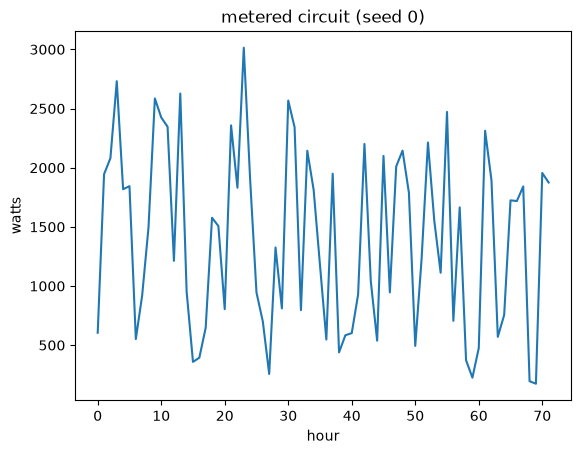

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ghost_circuit import GhostCircuit, evaluate

circuit = GhostCircuit.sample(seed=0)
x, y = circuit.x, circuit.y
plt.plot(y)
plt.xlabel('hour')
plt.ylabel('watts')
plt.title('metered circuit (seed 0)')


def correlated(x, y):
    """ every device whose on / off pattern correlates with the meter """
    r = np.array([np.corrcoef(x[:, i], y)[0, 1] for i in range(x.shape[1])])
    return np.where(r > .2)[0]


print(circuit.score(correlated(x, y)))
evaluate(correlated);